# load file

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
import matplotlib.pyplot as plt


(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1268s 7us/step


# image flatten, make KFold

k = (1-17) & metrics = [euclidian, manhattan]

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
import cv2
import numpy as np
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,)
# flatten train
train_images = train_images.reshape(len(train_images), -1)
train_labels = train_labels.reshape(-1)
# flatten test
test_images = test_images.reshape(len(test_images), -1)
test_labels = test_labels.reshape(-1)

# 54cross validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)


k_list = [1, 3, 5, 7, 9, 11, 13, 15, 17]
metrics=['euclidean', 'manhattan']

**Design**
- Hyperparameters are evaluated using 5-fold cross-validation (the validation split).
  Besides accuracy, we also look at F1, recall, and precision, and check whether the best k and distance metric differ for each evaluation criterion.
- For each criterion, we find the best k and best metric, then train on the full training set (not just the validation folds) and obtain the test results.

**Exception:** i wanted to use the entire training set, but the run time was too long, so only 10,000 samples were used for cross-validation.

In [3]:
import pandas as pd

N_CV = 10000  # Too slow....
cv_images = train_images[:N_CV]
cv_labels = train_labels[:N_CV]

rows = []
best_acc, best_k, best_met = 0, None, None
for met in metrics:
    for k in k_list:
        knn = KNeighborsClassifier(n_neighbors=k, metric=met, n_jobs=-1)

        fold_accuracies, fold_precs, fold_recs, fold_f1s = [], [], [], []

        for train_index, test_index in kfold.split(cv_images):
            X_train, X_test = cv_images[train_index], cv_images[test_index]
            y_train, y_test = cv_labels[train_index], cv_labels[test_index]
            knn.fit(X_train, y_train)
            y_pred = knn.predict(X_test)

            fold_accuracies.append(accuracy_score(y_test, y_pred))
            fold_precs.append(precision_score(y_test, y_pred, average='macro'))
            fold_recs.append(recall_score(y_test, y_pred, average='macro'))
            fold_f1s.append(f1_score(y_test, y_pred, average='macro'))
        # evaluate hyperparameter with mean of 5 fold
        mean_acc  = np.mean(fold_accuracies)
        mean_prec = np.mean(fold_precs)
        mean_rec  = np.mean(fold_recs)
        mean_f1   = np.mean(fold_f1s)

        print('k = %d, metric = %s | acc = %.4f, prec = %.4f, rec = %.4f, f1 = %.4f'
              % (k, met, mean_acc, mean_prec, mean_rec, mean_f1))

        rows.append({'distance': met, 'k': k,
                     'accuracy': mean_acc, 'precision': mean_prec,
                     'recall': mean_rec, 'f1': mean_f1})

        #find out best k value & metrix
        if mean_acc > best_acc:
            best_acc = mean_acc
            best_met = met
            best_k = k

k = 1, metric = euclidean | acc = 0.2851, prec = 0.3420, rec = 0.2835, f1 = 0.2766
k = 3, metric = euclidean | acc = 0.2743, prec = 0.3714, rec = 0.2721, f1 = 0.2560
k = 5, metric = euclidean | acc = 0.2848, prec = 0.3725, rec = 0.2824, f1 = 0.2639
k = 7, metric = euclidean | acc = 0.2851, prec = 0.3817, rec = 0.2827, f1 = 0.2622
k = 9, metric = euclidean | acc = 0.2876, prec = 0.3883, rec = 0.2853, f1 = 0.2635
k = 11, metric = euclidean | acc = 0.2844, prec = 0.3865, rec = 0.2822, f1 = 0.2581
k = 13, metric = euclidean | acc = 0.2832, prec = 0.3933, rec = 0.2807, f1 = 0.2556
k = 15, metric = euclidean | acc = 0.2852, prec = 0.4012, rec = 0.2827, f1 = 0.2567
k = 17, metric = euclidean | acc = 0.2868, prec = 0.3992, rec = 0.2842, f1 = 0.2576
k = 1, metric = manhattan | acc = 0.3080, prec = 0.3584, rec = 0.3067, f1 = 0.3051
k = 3, metric = manhattan | acc = 0.2959, prec = 0.3835, rec = 0.2938, f1 = 0.2847
k = 5, metric = manhattan | acc = 0.3142, prec = 0.3879, rec = 0.3121, f1 = 0.3028



- result: Validation was evaluated with accuracy, F1, recall, and precision separately, but the best hyperparameters were the same for all of them: k = 13 with the Manhattan distance.


In [6]:
df = pd.DataFrame(rows)
print(df.to_string(index=False))

print("Best k:", best_k)
print("Best metric:", best_met)
print("Best accuracy:", best_acc)

final_knn = KNeighborsClassifier(n_neighbors=best_k, metric=best_met, n_jobs=-1)
final_knn.fit(train_images, train_labels)
y_pred = final_knn.predict(test_images)

test_acc  = accuracy_score(test_labels, y_pred)
test_f1   = f1_score(test_labels, y_pred, average='macro')
test_prec = precision_score(test_labels, y_pred, average='macro')
test_rec  = recall_score(test_labels, y_pred, average='macro')

print("Test Accuracy:", test_acc)
print("Test F1 Score:", test_f1)
print("Test Precision:", test_prec)
print("Test Recall:", test_rec)

 distance  k  accuracy  precision  recall     f1
euclidean  1    0.2851     0.3420  0.2835 0.2766
euclidean  3    0.2743     0.3714  0.2721 0.2560
euclidean  5    0.2848     0.3725  0.2824 0.2639
euclidean  7    0.2851     0.3817  0.2827 0.2622
euclidean  9    0.2876     0.3883  0.2853 0.2635
euclidean 11    0.2844     0.3865  0.2822 0.2581
euclidean 13    0.2832     0.3933  0.2807 0.2556
euclidean 15    0.2852     0.4012  0.2827 0.2567
euclidean 17    0.2868     0.3992  0.2842 0.2576
manhattan  1    0.3080     0.3584  0.3067 0.3051
manhattan  3    0.2959     0.3835  0.2938 0.2847
manhattan  5    0.3142     0.3879  0.3121 0.3028
manhattan  7    0.3130     0.3950  0.3107 0.2998
manhattan  9    0.3167     0.3938  0.3144 0.3010
manhattan 11    0.3165     0.3983  0.3141 0.3018
manhattan 13    0.3218     0.4075  0.3194 0.3055
manhattan 15    0.3182     0.4040  0.3161 0.3011
manhattan 17    0.3140     0.4013  0.3116 0.2963
Best k: 13
Best metric: manhattan
Best accuracy: 0.3218
Test Accuracy

Test Accuracy: 0.3722
/Test F1 Score: 0.3652322817425958
/Test Precision: 0.46265188552506437
/Test Recall: 0.3722

train Accuracy = 0.3218 /train f1 = 0.3055/train Precision = 0.4075/train Recall = 0.3194

cause of the gap:
- val: used part of the data
- test: used all data

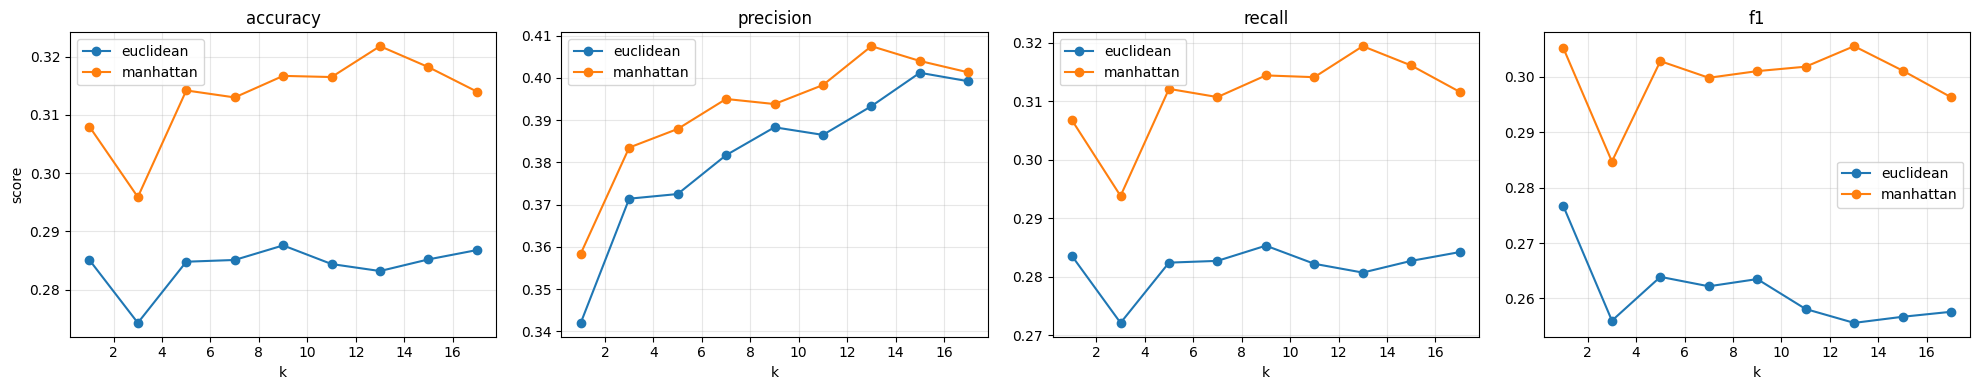

Best accuracy : k=13, distance=manhattan, accuracy=0.3218
Best precision: k=13, distance=manhattan, precision=0.4075
Best recall   : k=13, distance=manhattan, recall=0.3194
Best f1       : k=13, distance=manhattan, f1=0.3055


In [7]:
import matplotlib.pyplot as plt

metrics = [m for m in ['accuracy', 'precision', 'recall', 'f1'] if m in df.columns]

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4), sharex=True)
axes = np.atleast_1d(axes)

for ax, m in zip(axes, metrics):
    for dist, g in df.groupby('distance'):
        g = g.sort_values('k')
        ax.plot(g['k'], g[m], marker='o', label=dist)
    ax.set_title(m)
    ax.set_xlabel('k')
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel('score')
plt.tight_layout()
plt.show()

# 지표별 최고 조합
for m in metrics:
    b = df.loc[df[m].idxmax()]
    print(f"Best {m:9s}: k={int(b['k'])}, distance={b['distance']}, {m}={b[m]:.4f}")